In [19]:
%pip install numpy pandas scipy openpyxl matplotlib

Note: you may need to restart the kernel to use updated packages.


In [20]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import scipy
from scipy.io import loadmat
from scipy.io.matlab import MatlabOpaque
from IPython.display import display

print("Python executable:", sys.executable)
print("SciPy version:", scipy.__version__)
print("Pandas version:", pd.__version__)

Python executable: /home/souhail/DataMining/venv/bin/python
SciPy version: 1.18.1
Pandas version: 3.0.6


In [21]:
current = Path.cwd().resolve()

ROOT = next(
    (
        folder
        for folder in [current, *current.parents]
        if (folder / "data" / "raw").is_dir()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/raw/. "
        "Start JupyterLab from your project directory."
    )

RAW_DIR = ROOT / "data" / "raw"

print("Project directory:", ROOT)
print("Raw data directory:", RAW_DIR)

Project directory: /home/souhail/DataMining
Raw data directory: /home/souhail/DataMining/data/raw


In [22]:
file_rows = [
    {
        "filename": path.name,
        "extension": path.suffix,
        "size_mb": round(path.stat().st_size / 1024**2, 3),
    }
    for path in sorted(RAW_DIR.iterdir())
    if path.is_file() and not path.name.startswith("~$")
]

files = pd.DataFrame(
    file_rows,
    columns=["filename", "extension", "size_mb"],
)

display(files)

,filename,extension,size_mb
0,190304A_E_0000d.mat,.mat,50.546
1,190304A_E_0000h.mat,.mat,0.002
2,191113A_D_0000d.mat,.mat,41.698
3,191113A_D_0000h.mat,.mat,0.002
4,200625A_F_0000d.mat,.mat,27.558
5,200625A_F_0000h.mat,.mat,0.001
6,210204B_C_0000d.mat,.mat,29.910
7,210204B_C_0000h.mat,.mat,0.001
8,210208B_G_0000d.mat,.mat,26.684
9,210208B_G_0000h.mat,.mat,0.001


In [23]:
recording_id = "230102B_F_0000"

data_path = RAW_DIR / f"{recording_id}d.mat"
header_path = RAW_DIR / f"{recording_id}h.mat"
annotations_path = RAW_DIR / "Crises absences.xlsx"

for path in [data_path, header_path, annotations_path]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing file: {path}")

    print("Found:", path.name)

Found: 230102B_F_0000d.mat
Found: 230102B_F_0000h.mat
Found: Crises absences.xlsx


In [24]:
loaded_files = {}

for path in [data_path, header_path]:
    print(f"\nLoading: {path.name}")

    try:
        loaded_files[path.name] = loadmat(
            str(path),
            simplify_cells=True,
        )

        public_names = [
            name
            for name in loaded_files[path.name]
            if not name.startswith("__")
        ]

        print("Variables:", public_names)

    except Exception as error:
        print(f"Failed: {type(error).__name__}: {error}")


Loading: 230102B_F_0000d.mat
Variables: ['output_d']

Loading: 230102B_F_0000h.mat
Variables: ['output_h']


In [25]:
required_files = [data_path.name, header_path.name]

missing = [
    name for name in required_files
    if name not in loaded_files
]

if missing:
    raise RuntimeError(
        f"Loading failed for: {missing}. Check the previous cell."
    )

signal_contents = {
    name: value
    for name, value in loaded_files[data_path.name].items()
    if not name.startswith("__")
}

header_contents = {
    name: value
    for name, value in loaded_files[header_path.name].items()
    if not name.startswith("__")
}

print("Data variables:", list(signal_contents))
print("Header variables:", list(header_contents))

Data variables: ['output_d']
Header variables: ['output_h']


In [26]:
def describe(value, name="root", depth=0, max_depth=4):
    indent = "  " * depth

    if isinstance(value, MatlabOpaque):
        print(f"{indent}{name}: opaque MATLAB object")
        print(f"{indent}  Wrapper shape: {value.shape}")

        fields = value.dtype.names or ()
        print(f"{indent}  Metadata fields: {fields}")

        for field in ("_TypeSystem", "_Class"):
            if field in fields:
                print(f"{indent}  {field}: {value[field].tolist()}")

        print(f"{indent}  EEG samples have not been decoded.")

    elif isinstance(value, dict):
        print(f"{indent}{name}: dictionary")

        if depth < max_depth:
            for key, item in value.items():
                describe(item, str(key), depth + 1, max_depth)

    elif isinstance(value, np.ndarray):
        print(
            f"{indent}{name}: "
            f"shape={value.shape}, dtype={value.dtype}"
        )

        if value.dtype.kind in "biufc":
            print(f"{indent}  Preview: {value.ravel()[:8]}")
        else:
            print(f"{indent}  Preview: {repr(value)[:300]}")

    else:
        print(f"{indent}{name}: {repr(value)[:300]}")

In [27]:
print("DATA FILE")
describe(signal_contents)

print("\nHEADER FILE")
describe(header_contents)

DATA FILE
root: dictionary
  output_d: opaque MATLAB object
    Wrapper shape: (1,)
    Metadata fields: ('_TypeSystem', '_Class', '_ObjectMetadata')
    _TypeSystem: ['MCOS']
    _Class: ['timetable']
    EEG samples have not been decoded.

HEADER FILE
root: dictionary
  output_h: opaque MATLAB object
    Wrapper shape: (1,)
    Metadata fields: ('_TypeSystem', '_Class', '_ObjectMetadata')
    _TypeSystem: ['MCOS']
    _Class: ['timetable']
    EEG samples have not been decoded.


In [28]:
annotations = pd.read_excel(
    annotations_path,
    sheet_name="Feuil1",
    header=0,
)

annotations = annotations.rename(
    columns={annotations.columns[0]: "recording_id"}
)

annotations.columns = [
    str(column).strip()
    for column in annotations.columns
]

annotations = annotations.dropna(how="all")

print("Table shape:", annotations.shape)
display(annotations.head())

Table shape: (26, 36)


,recording_id,Sexe,Age,NombreCE,TypeAbs,DebCE1,FinCE1,DebCE2,FinCE2,DebCE3,...,FinCE11,DebCE12,FinCE12,Intercrit1,Intercrit2,Intercrit3,Intercrit4,Intercrit5,Intercrit6,Intercrit7
0,190304A-E,M,17.0,1.0,NaN,0.441042,0.441123,NaN,NaN,NaN,...,NaN,NaN,NaN,0.432396,NaN,NaN,NaN,NaN,NaN,NaN
1,191113A-D,F,25.0,2.0,NaN,0.443900,0.444051,0.445914,0.445972,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,200625A-F,M,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,210204B-C,F,5.0,6.0,NaN,0.431829,0.431887,0.433669,0.433727,0.436308,...,NaN,NaN,NaN,0.433796,0.433808,0.433819,0.434815,0.434873,0.438391,0.439398
4,210208B-G,F,14.0,4.0,NaN,0.471678,0.471794,0.472500,0.472581,0.475359,...,NaN,NaN,NaN,0.470359,0.470370,0.471412,0.471574,0.473403,0.473866,NaN


In [29]:
column_fixes = {
    "DebutCE5": "DebCE5",
    "DebtCE11": "DebCE11",
}

for old_name, new_name in column_fixes.items():
    if old_name in annotations.columns:
        if new_name in annotations.columns:
            raise ValueError(
                f"Both {old_name} and {new_name} exist. "
                "Inspect them before combining."
            )

        annotations = annotations.rename(
            columns={old_name: new_name}
        )

missing_id = (
    annotations["recording_id"].isna()
    | annotations["recording_id"]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
)

unidentified_rows = annotations.loc[missing_id].copy()

print("Rows without a recording identifier:")
display(unidentified_rows)

# Keep these rows separately until their meaning is understood.
annotations = annotations.loc[~missing_id].copy()

print("Rows with recording identifiers:", len(annotations))

Rows without a recording identifier:


,recording_id,Sexe,Age,NombreCE,TypeAbs,DebCE1,FinCE1,DebCE2,FinCE2,DebCE3,...,FinCE11,DebCE12,FinCE12,Intercrit1,Intercrit2,Intercrit3,Intercrit4,Intercrit5,Intercrit6,Intercrit7
24,NaN,NaN,NaN,98.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1048573,NaN,NaN,NaN,196.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Rows with recording identifiers: 24


In [30]:
column_summary = pd.DataFrame({
    "dtype": annotations.dtypes.astype(str),
    "missing_count": annotations.isna().sum(),
    "non_missing_count": annotations.notna().sum(),
})

display(column_summary)

,dtype,missing_count,non_missing_count
recording_id,str,0,24
Sexe,str,0,24
Age,float64,0,24
NombreCE,float64,1,23
TypeAbs,str,23,1
DebCE1,float64,1,23
FinCE1,float64,1,23
DebCE2,float64,5,19
FinCE2,float64,5,19
DebCE3,float64,11,13


In [31]:
def normalize_id(value):
    if pd.isna(value):
        return ""

    return str(value).strip().upper().replace("-", "_")


# "230102B_F_0000" becomes "230102B_F".
base_id = recording_id.rsplit("_", 1)[0]

matches = annotations.loc[
    annotations["recording_id"].map(normalize_id)
    == normalize_id(base_id)
].copy()

print("Recording identifier:", base_id)
print("Matching annotation rows:", len(matches))

if matches.empty:
    print("No exact match. Available identifiers:")
    display(annotations[["recording_id"]])
else:
    display(matches.T)

Recording identifier: 230102B_F
Matching annotation rows: 1


,17
recording_id,230102B-F
Sexe,F
Age,7.0
NombreCE,9.0
TypeAbs,NaN
DebCE1,0.504062
FinCE1,0.504167
DebCE2,0.506053
FinCE2,0.506238
DebCE3,0.506597


In [32]:
import re

if len(matches) != 1:
    raise ValueError(
        f"Expected one annotation row, found {len(matches)}. "
        "Resolve the recording match before continuing."
    )

row = matches.iloc[0]

seizure_numbers = sorted({
    int(match.group(1))
    for column in annotations.columns
    if (match := re.fullmatch(r"DebCE(\d+)", column))
})

interval_rows = []

for number in seizure_numbers:
    start_column = f"DebCE{number}"
    end_column = f"FinCE{number}"

    start = row[start_column]
    end = row.get(end_column, np.nan)

    if pd.isna(start) and pd.isna(end):
        continue

    interval_rows.append({
        "seizure_number": number,
        "start_raw": start,
        "end_raw": end,
        "complete_pair": pd.notna(start) and pd.notna(end),
    })

seizure_intervals_raw = pd.DataFrame(
    interval_rows,
    columns=[
        "seizure_number",
        "start_raw",
        "end_raw",
        "complete_pair",
    ],
)

display(seizure_intervals_raw)

print("Reported NombreCE:", row.get("NombreCE", "not available"))
print("Non-empty pairs:", len(seizure_intervals_raw))
print(
    "Complete pairs:",
    int(seizure_intervals_raw["complete_pair"].sum()),
)

,seizure_number,start_raw,end_raw,complete_pair
0,1,0.504062,0.504167,True
1,2,0.506053,0.506238,True
2,3,0.506597,0.506713,True
3,4,0.507708,0.507870,True
4,5,0.508646,0.508738,True
5,6,0.510810,0.511042,True
6,7,0.514456,0.514734,True
7,8,0.515637,0.515833,True
8,9,0.517315,0.517512,True


Reported NombreCE: 9.0
Non-empty pairs: 9
Complete pairs: 9


In [33]:
incomplete = seizure_intervals_raw.loc[
    ~seizure_intervals_raw["complete_pair"]
]

print("Incomplete seizure pairs:", len(incomplete))

if not incomplete.empty:
    display(incomplete)

reported_count = row.get("NombreCE", np.nan)
extracted_count = int(
    seizure_intervals_raw["complete_pair"].sum()
)

if pd.notna(reported_count):
    if extracted_count == reported_count:
        print(f"Count check passed: {extracted_count} complete pairs.")
    else:
        print(
            f"Count mismatch: reported {reported_count}, "
            f"extracted {extracted_count}."
        )
else:
    print("No reported count available for comparison.")

Incomplete seizure pairs: 0
Count check passed: 9 complete pairs.


In [34]:
import io
import numpy as np
import pandas as pd
from scipy.io import loadmat
from scipy.io.matlab._mio5 import MatFile5Reader


def read_object_storage(path):
    # Keep the complete file contents, including internal storage.
    contents = loadmat(str(path))

    workspace = contents.get("__function_workspace__")

    if workspace is None:
        raise ValueError("Expected embedded MATLAB storage was not found.")

    raw = workspace.tobytes()

    if raw[2:4] != b"IM":
        raise ValueError("This loader expects little-endian MATLAB storage.")

    stream = io.BytesIO(raw)

    reader = MatFile5Reader(stream, byte_order="<")
    reader.initialize_read()

    # Skip the embedded storage header.
    stream.seek(8)

    header, _ = reader.read_var_header()
    root = reader.read_var_array(header)

    if "MCOS" not in (root.dtype.names or ()):
        raise ValueError("Expected MCOS object storage was not found.")

    wrapper = root["MCOS"][0, 0]

    # Field naming differs between SciPy versions.
    payload_field = wrapper.dtype.names[-1]
    pool = wrapper[payload_field][0].ravel()

    return pool

In [35]:
pool = read_object_storage(data_path)

# These positions were inspected in your uploaded recording.
table_storage = pool[4]

required_fields = {"data", "varNames", "numRows", "numVars"}

if not required_fields.issubset(table_storage.dtype.names or ()):
    raise ValueError("Unexpected timetable layout.")

table = table_storage[0, 0]

channel_names = [
    str(name.item())
    for name in table["varNames"].ravel()
]

channel_blocks = table["data"].ravel()

n_blocks = int(table["numRows"].item())
n_channels = int(table["numVars"].item())

if len(channel_names) != n_channels or len(channel_blocks) != n_channels:
    raise ValueError("Channel metadata does not match the stored data.")

samples_per_block = np.asarray(
    channel_blocks[0].ravel()[0]
).size

channel_arrays = []

for name, blocks in zip(channel_names, channel_blocks):
    blocks = blocks.ravel()

    if len(blocks) != n_blocks:
        raise ValueError(f"Unexpected block count for {name}.")

    if any(np.asarray(block).size != samples_per_block for block in blocks):
        raise ValueError(f"Inconsistent block lengths for {name}.")

    samples = np.concatenate([
        np.asarray(block, dtype=float).ravel()
        for block in blocks
    ])

    channel_arrays.append(samples)

signal = np.column_stack(channel_arrays)

print("Signal shape:", signal.shape)
print("Blocks:", n_blocks)
print("Samples per block:", samples_per_block)
print("Channels:", channel_names)

Signal shape: (313600, 21)
Blocks: 1225
Samples per block: 256
Channels: ['EEGFp1', 'EEGFp2', 'EEGF7', 'EEGF3', 'EEGFz', 'EEGF4', 'EEGF8', 'EEGT4', 'EEGC4', 'EEGCz', 'EEGC3', 'EEGT3', 'EEGT5', 'EEGP3', 'EEGPz', 'EEGP4', 'EEGT6', 'EEGO2', 'EEGO1', 'SLI', 'ECG']


In [36]:
block_start_ms = np.asarray(pool[2], dtype=float).ravel()

if len(block_start_ms) != n_blocks:
    raise ValueError("Block timestamps do not match the number of blocks.")

block_start_seconds = block_start_ms / 1000.0
block_steps = np.diff(block_start_seconds)

if (
    not np.isfinite(block_start_seconds).all()
    or np.any(block_steps <= 0)
):
    raise ValueError("Invalid block timestamps.")

block_duration = float(np.median(block_steps))

if not np.allclose(block_steps, block_duration):
    raise ValueError("Irregular block timing requires additional handling.")

fs = samples_per_block / block_duration

time_seconds = (
    block_start_seconds[:, None]
    + np.arange(samples_per_block)[None, :] / fs
).ravel()

duration_seconds = (
    time_seconds[-1] - time_seconds[0] + 1 / fs
)

print(f"Sampling frequency: {fs:.1f} Hz")
print(f"Duration: {duration_seconds:.1f} seconds")
print(f"Last sample timestamp: {time_seconds[-1]:.6f} seconds")

Sampling frequency: 256.0 Hz
Duration: 1225.0 seconds
Last sample timestamp: 1224.996094 seconds


In [37]:
eeg = pd.DataFrame(signal, columns=channel_names)
eeg.insert(0, "Time", time_seconds)

eeg_channels = [
    name for name in channel_names
    if name.startswith("EEG")
]

other_channels = [
    name for name in channel_names
    if name not in eeg_channels
]

print("EEG channels:", len(eeg_channels))
print("Other channels:", other_channels)

display(eeg.head())

quality = pd.DataFrame({
    "channel": channel_names,
    "missing_values": np.isnan(signal).sum(axis=0),
    "infinite_values": np.isinf(signal).sum(axis=0),
})

display(quality)

EEG channels: 19
Other channels: ['SLI', 'ECG']


,Time,EEGFp1,EEGFp2,EEGF7,EEGF3,EEGFz,EEGF4,EEGF8,EEGT4,EEGC4,...,EEGT3,EEGT5,EEGP3,EEGPz,EEGP4,EEGT6,EEGO2,EEGO1,SLI,ECG
0,0.000000,519.155642,809.653696,631.202335,-19.420233,2631.396887,1.342412,818.961089,8.322957,407.108949,...,358.961089,92.984436,678.813230,246.735409,181.941634,-165.116732,135.225681,329.428016,0.089494,3126.657588
1,0.003906,329.785992,591.287938,443.801556,-208.073930,2528.657588,-198.587549,594.509728,-169.591440,187.848249,...,169.949416,-96.743191,488.727626,40.003891,-104.439689,-350.548638,-51.638132,152.945525,0.089494,3309.941634
2,0.007812,199.840467,466.354086,312.066148,-339.093385,2381.171206,-329.607004,466.712062,-299.000000,39.824903,...,41.972763,-230.268482,358.424125,-91.552529,-242.976654,-476.914397,-178.361868,15.840467,0.089494,3449.910506
3,0.011719,298.642023,601.132296,412.299611,-237.785992,2620.657588,-219.529183,607.396887,-205.031128,161.178988,...,146.322957,-128.424125,461.879377,24.252918,-48.237354,-373.817121,-75.085603,103.902724,0.089494,3377.778210
4,0.015625,497.856031,818.961089,617.957198,-32.486381,2880.369650,-9.038911,835.070039,-3.132296,401.739300,...,353.949416,82.603113,670.937743,242.797665,234.206226,-166.190661,134.330739,310.276265,0.089494,3196.642023


,channel,missing_values,infinite_values
0,EEGFp1,0,0
1,EEGFp2,0,0
2,EEGF7,0,0
3,EEGF3,0,0
4,EEGFz,0,0
5,EEGF4,0,0
6,EEGF8,0,0
7,EEGT4,0,0
8,EEGC4,0,0
9,EEGCz,0,0


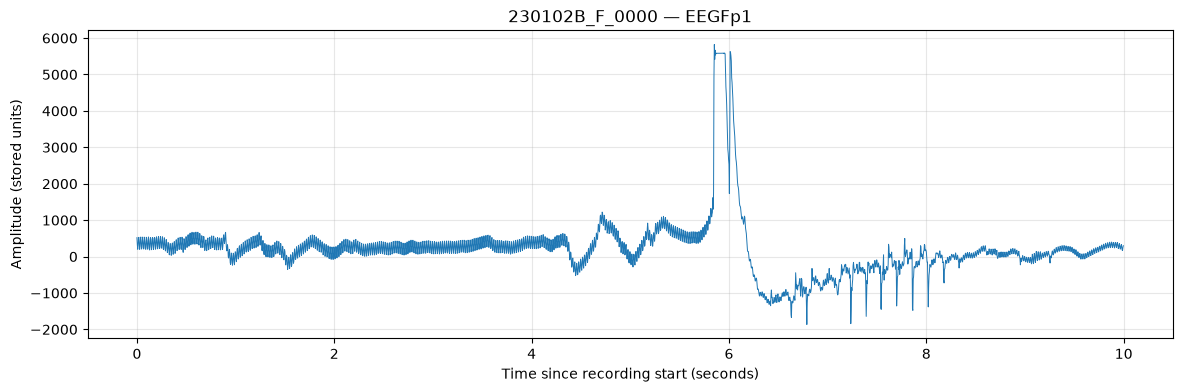

In [38]:
import matplotlib.pyplot as plt

channel = "EEGFp1"

start_seconds = 0
end_seconds = 10

selection = (
    (eeg["Time"] >= start_seconds)
    & (eeg["Time"] < end_seconds)
)

fig, ax = plt.subplots(figsize=(14, 4))

ax.plot(
    eeg.loc[selection, "Time"],
    eeg.loc[selection, channel],
    linewidth=0.7,
)

ax.set(
    title=f"{recording_id} — {channel}",
    xlabel="Time since recording start (seconds)",
    ylabel="Amplitude (stored units)",
)

ax.grid(alpha=0.3)
plt.show()